# 04 — Extração de Características Reais no BETA (`Narrow SNR`, `Wide SNR`, Espectrais e Temporais)

> **Adaptação de:** `SSVEP/beta_ml.ipynb`, `Focus/src/snr_feature.ipynb` e `SomeFeatures/04-features.ipynb` ([bneurd/tutoriais](https://github.com/bneurd/tutoriais)).

## O que foi aprimorado em relação ao rascunho original `beta_ml.ipynb`?
No notebook original do repositório `tutoriais`, os cálculos de `narrow-band SNR` e `wide-band SNR` haviam sido demonstrados sobre **dados aleatórios fictícios** (`np.random.normal(size=(160, 64, 750))`), forçando `estimated_background_noise = 1.0` para evitar logaritmo de números negativos (`NaN`).

Aqui aplicamos a formulação física exata sobre os **dados reais do Dataset BETA**:
1. **Ruído de Fundo Real (`psd_noise`):** Medido diretamente nos trechos sem estímulo de cada tentativa (`0.0 – 0.5 s` e `2.5 – 3.0 s`);
2. **Sinal Estimulado (`psd_stim`):** Medido na janela SSVEP estacionária (`0.63 – 2.5 s`, após os `130 ms` de latência visual) com `n_fft = 1250` (resolução exata de `0.2 Hz` cravada nos 40 alvos);
3. **4 Matrizes Espectrais `(160, C, 40)` $\rightarrow$ `(160, C * 160)`:**
   * `narrow_snr` (dB): potência no alvo vs. frequências vizinhas (Eq. 3 do artigo BETA);
   * `wide_snr` (dB): potência harmônica vs. potência total 8–64 Hz (Eq. 4 do artigo BETA);
   * `basal_snr` (dB): potência estimulada vs. ruído basal medido antes/depois do estímulo;
   * `target_amp`: amplitude harmônica combinada;
4. **Características Clássicas (`SomeFeatures`):** `VAR`, `RMS`, `FMD` e `MMDF` por canal.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT != PROJECT_ROOT.parent and not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import matplotlib.pyplot as plt

from src.bneurd_beta import (
    PROCESSED_DATA_DIR,
    butter_bandpass,
    butter_notch,
    extract_beta_ml_features,
    extract_classic_channel_features,
    load_beta_subject,
)

# 1. Carrega todos os 64 canais de S1 para comprovar a dimensionalidade (160, 10240) de tunning.ipynb
X_s1_64, y_freqs_s1, y_cls_s1, blocks_s1, meta_64 = load_beta_subject(1, channels="all", window="full")
X_s1_64_filt = butter_bandpass(butter_notch(X_s1_64, 50.0, fs=250), 8.0, 64.0, fs=250)

feats_64 = extract_beta_ml_features(X_s1_64_filt)
classic_64 = extract_classic_channel_features(X_s1_64_filt[:, :, 157:625])

print("Verificação das dimensões em 64 canais (conforme previsto em tunning.ipynb):")
print(" - narrow_snr    :", feats_64["narrow_snr"].shape, "| NaNs:", np.isnan(feats_64["narrow_snr"]).sum())
print(" - wide_snr      :", feats_64["wide_snr"].shape,   "| NaNs:", np.isnan(feats_64["wide_snr"]).sum())
print(" - basal_snr     :", feats_64["basal_snr"].shape,  "| NaNs:", np.isnan(feats_64["basal_snr"]).sum())
print(" - target_amp    :", feats_64["target_amp"].shape, "| NaNs:", np.isnan(feats_64["target_amp"]).sum())
print(" - feature_matrix:", feats_64["feature_matrix"].shape, "-> (160 amostras, 64 canais * 40 alvos * 4 = 10240)")
print(" - classic (VAR, RMS, FMD, MMDF):", classic_64.shape, "-> (160 amostras, 64 * 4 = 256)")

Verificação das dimensões em 64 canais (conforme previsto em tunning.ipynb):
 - narrow_snr    : (160, 64, 40) | NaNs: 0
 - wide_snr      : (160, 64, 40) | NaNs: 0
 - basal_snr     : (160, 64, 40) | NaNs: 0
 - target_amp    : (160, 64, 40) | NaNs: 0
 - feature_matrix: (160, 10240) -> (160 amostras, 64 canais * 40 alvos * 4 = 10240)
 - classic (VAR, RMS, FMD, MMDF): (160, 256) -> (160 amostras, 64 * 4 = 256)


### 2. Extração nos 9 Canais Parieto-Occipitais e Visualização da Diagonal de Ressonância SSVEP
Ao observar a média de `narrow_snr` e `basal_snr` nos 9 canais visuais para cada classe real (0 a 39) vs. cada frequência candidata (8.0 a 15.8 Hz), vemos uma **diagonal nítida**, provando que cada estímulo eleva seletivamente a SNR na sua exata frequência!

Matrizes de características salvas: (160, 1440)


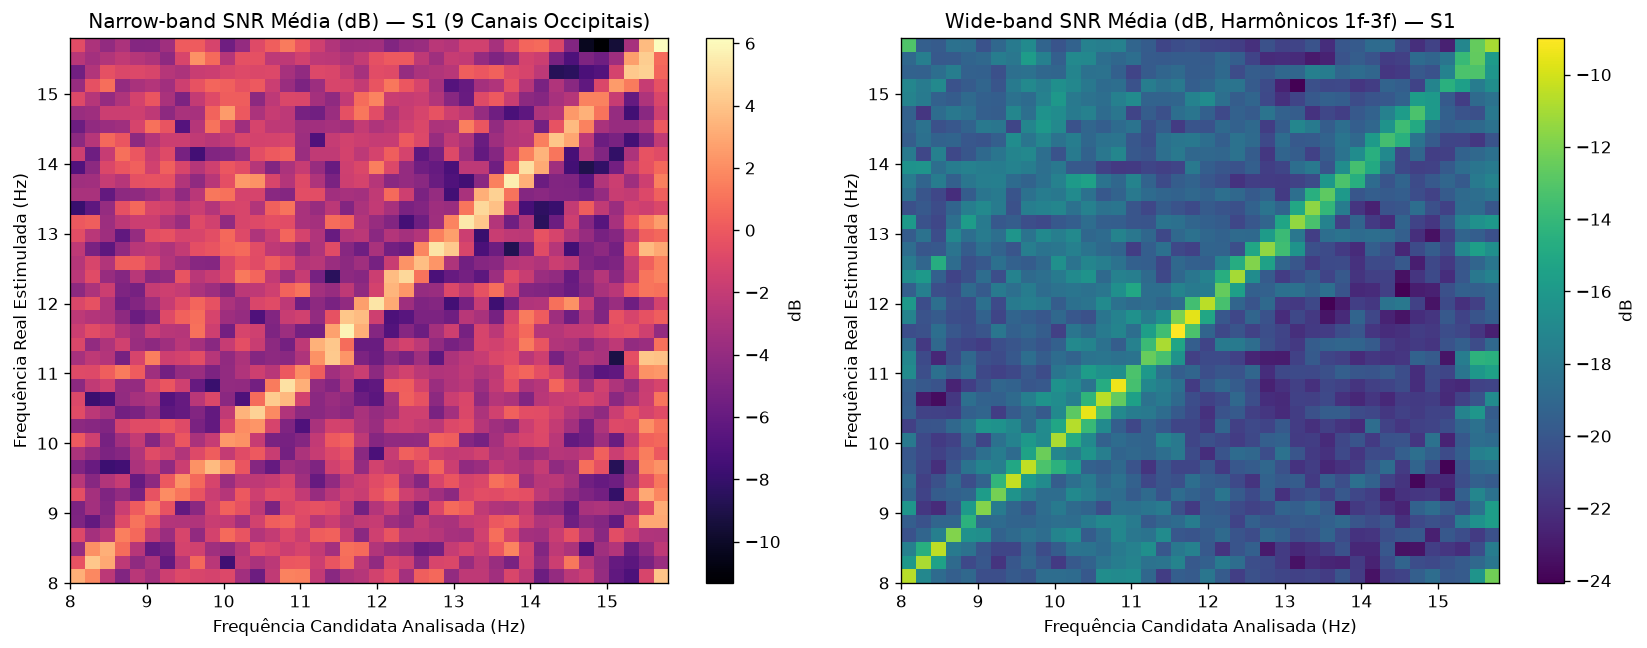

In [2]:
X_s1_9, _, _, _, meta_9 = load_beta_subject(1, channels="9ch", window="full")
X_s1_9_filt = butter_bandpass(butter_notch(X_s1_9, 50.0, fs=250), 8.0, 64.0, fs=250)
feats_9 = extract_beta_ml_features(X_s1_9_filt)

PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)
np.save(PROCESSED_DATA_DIR / "beta_s1_features_64ch.npy", feats_64["feature_matrix"])
np.save(PROCESSED_DATA_DIR / "beta_s1_features_9ch.npy", feats_9["feature_matrix"])
np.save(PROCESSED_DATA_DIR / "beta_s1_y_class.npy", y_cls_s1)
print("Matrizes de características salvas:", feats_9["feature_matrix"].shape)

# Calcula matriz média (40 classes reais x 40 frequências candidatas) sobre os 4 blocos e 9 canais
diag_narrow = np.zeros((40, 40))
diag_wide = np.zeros((40, 40))
for cls_idx in range(40):
    trial_mask = (y_cls_s1 == cls_idx)
    diag_narrow[cls_idx] = feats_9["narrow_snr"][trial_mask].mean(axis=(0, 1))
    diag_wide[cls_idx] = feats_9["wide_snr"][trial_mask].mean(axis=(0, 1))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

im0 = axes[0].imshow(diag_narrow, aspect="auto", origin="lower", cmap="magma",
                     extent=[8.0, 15.8, 8.0, 15.8])
axes[0].set_title("Narrow-band SNR Média (dB) — S1 (9 Canais Occipitais)")
axes[0].set_xlabel("Frequência Candidata Analisada (Hz)")
axes[0].set_ylabel("Frequência Real Estimulada (Hz)")
plt.colorbar(im0, ax=axes[0], label="dB")

im1 = axes[1].imshow(diag_wide, aspect="auto", origin="lower", cmap="viridis",
                     extent=[8.0, 15.8, 8.0, 15.8])
axes[1].set_title("Wide-band SNR Média (dB, Harmônicos 1f-3f) — S1")
axes[1].set_xlabel("Frequência Candidata Analisada (Hz)")
axes[1].set_ylabel("Frequência Real Estimulada (Hz)")
plt.colorbar(im1, ax=axes[1], label="dB")

plt.tight_layout()
plt.show()